# Conlang Translator
<a id="title"></a>

[Project Repo](https://github.com/Ethereal-Mining-Company/conlang-translator) \
Christopher Doupis \
December 6, 2026

<div class="alert alert-info" style="color: black;">
    
### AI USE DISCLAIMER & ACADEMIC INTEGRITY COMPLIANCE
In compliance with the [**National University Student Guidelines for Generative AI**](https://resources.nu.edu/ai/ai-guidelines), this project discloses the following tool usage:

* **Conceptual Framing & Brainstorming (AI-Informed):** **Google Gemini** was utilized as a supplemental learning resource to clarify core mathematical and analytical concepts across the assignment questions. 
* **Technical Execution & Boilerplate Generation (AI-Assisted):** **Google Gemini** was used to generate initial code structures and programming boilerplates. These templates were subsequently modified, debugged, and tailored to meet the specific requirements of each question.
* **Human Oversight, Validation Loops & Refinement (Author-Owned):** The author maintained complete conceptual control, process oversight, and ownership of the entire homework scope. All AI-assisted templates, code logic, and conceptual outputs were systematically reviewed and validated by the author to ensure academic accuracy and integrity.
* **Disclosure Statement (AI-Generated):** **Google Gemini** was utilized to structure and audit this text format to fulfill all institutional reporting standards.
</div>

### REFERENCES
#### Peer Reviewed and Scientific References

#### Generative AI & Software Tools
* **[Google.](https://google.com)** (2026). *Gemini* [Large language model]. https://google.com

In [3]:
import sys
from pathlib import Path

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.engine import DynamicTranslator
from src.models import MODEL_REGISTRY
from src.utils import load_config

cfg = load_config()
translator = DynamicTranslator(cfg["paths"]["languages_dir"])

print("Config Loaded:", list(cfg.keys()))
print("Registered Models:", list(MODEL_REGISTRY.keys()))
print("Available Languages:", translator.available_languages())

for name, prof in translator.profiles.items():
    print(f"\n[{name.upper()}]")
    print("  Loaded Files:", prof.loaded_sources)
    print("  Word Order:  ", prof.word_order, "| Adj Before Noun:", prof.adj_before_noun)
    print("  Affixes:     ", prof.affixes)
    print("  Vocabulary:  ", len(prof.eng_fallback), "words |", len(prof.eng_phrases), "phrases")

Config Loaded: ['runtime', 'paths', 'dataset', 'translator', 'models']
Registered Models: ['bilstm_crf', 'random_forest']
Available Languages: ['english', 'aelorian']

[AELORIAN]
  Loaded Files: ['aelorian.csv', 'aelorian.yaml', 'aelorian.txt', 'custom.txt']
  Word Order:   SVO | Adj Before Noun: True
  Affixes:      {'NOUN_PLUR': 'i', 'VERB_PAST': 'an', 'VERB_FUTURE': 'ar', 'VERB_PROG': 'in', 'ADJ_COMP': 'el', 'ADJ_SUPER': 'is'}
  Vocabulary:   7067 words | 629 phrases


In [4]:
import sys
from pathlib import Path

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.engine import DynamicTranslator
from src.features import download_ud_ewt, parse_conllu
from src.models import MODEL_REGISTRY, get_tagger, run_all_training
from src.utils import load_config, resolve_path
from src.visualizations import plot_model_head_to_head

cfg = load_config()
translator = DynamicTranslator(cfg["paths"]["languages_dir"])
print("Models:", list(MODEL_REGISTRY.keys()), "| Languages:", translator.available_languages())

Models: ['bilstm_crf', 'random_forest'] | Languages: ['english', 'aelorian']


,Split,Sentences,Tokens
0,Train,12544,204578
1,Validation (Dev),2001,25148
2,Test,2077,25094


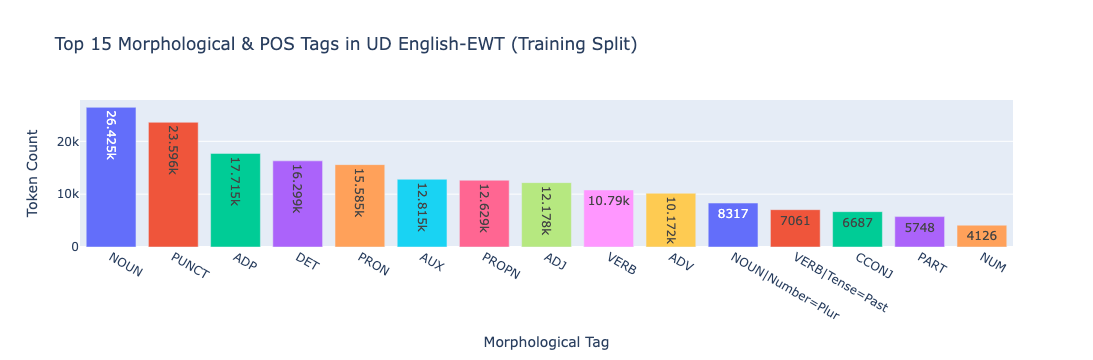

In [5]:
import pandas as pd
import plotly.express as px

paths = download_ud_ewt(cfg)
train_s, dev_s, test_s = parse_conllu(paths["train"]), parse_conllu(paths["dev"]), parse_conllu(paths["test"])

split_df = pd.DataFrame([
    {"Split": "Train", "Sentences": len(train_s), "Tokens": sum(len(s) for s in train_s)},
    {"Split": "Validation (Dev)", "Sentences": len(dev_s), "Tokens": sum(len(s) for s in dev_s)},
    {"Split": "Test", "Sentences": len(test_s), "Tokens": sum(len(s) for s in test_s)},
])
display(split_df)

all_labels = [tok["label"] for sent in train_s for tok in sent]
top_tags = pd.Series(all_labels).value_counts().head(15).reset_index()
top_tags.columns = ["Morphological Tag", "Token Count"]

fig_eda = px.bar(
    top_tags,
    x="Morphological Tag",
    y="Token Count",
    color="Morphological Tag",
    title="Top 15 Morphological & POS Tags in UD English-EWT (Training Split)",
    text_auto=True,
)
fig_eda.update_layout(showlegend=False)
fig_eda.write_html(resolve_path(cfg["paths"]["figures"]) / "eda_tag_distribution.html")
fig_eda.show()

In [6]:
run_all_training()

2026-11-16 16:56:52,961 | INFO | RF_Baseline -> Val Acc: 0.6165 (1.2s)
2026-11-16 16:56:57,516 | INFO | RF_Tuned -> Val Acc: 0.7923 (4.4s)
2026-11-16 16:58:09,358 | INFO | RF_Deep -> Val Acc: 0.9305 (71.5s)
2026-11-16 16:58:09,727 | INFO | Best Random Forest Test Acc: 0.9293 | Macro F1: 0.8705 | 0.156 ms/sent
2026-11-16 16:58:09,781 | INFO | 
                           precision    recall  f1-score   support

                      ADJ       0.94      0.84      0.89      1653
           ADJ|Degree=Cmp       0.88      0.88      0.88        48
           ADJ|Degree=Sup       0.88      0.97      0.92        87
                      ADP       0.94      0.96      0.95      2025
                      ADV       0.94      0.90      0.92      1191
                      AUX       0.98      0.99      0.98      1543
                    CCONJ       1.00      0.99      0.99       736
                      DET       0.98      0.98      0.98      1897
                     INTJ       0.94      0.74     

,Model,Test Accuracy,Macro F1,Latency (ms/sent)
0,Random Forest,0.9293,0.8705,0.156
1,BiLSTM-CRF,0.9083,0.8613,0.366


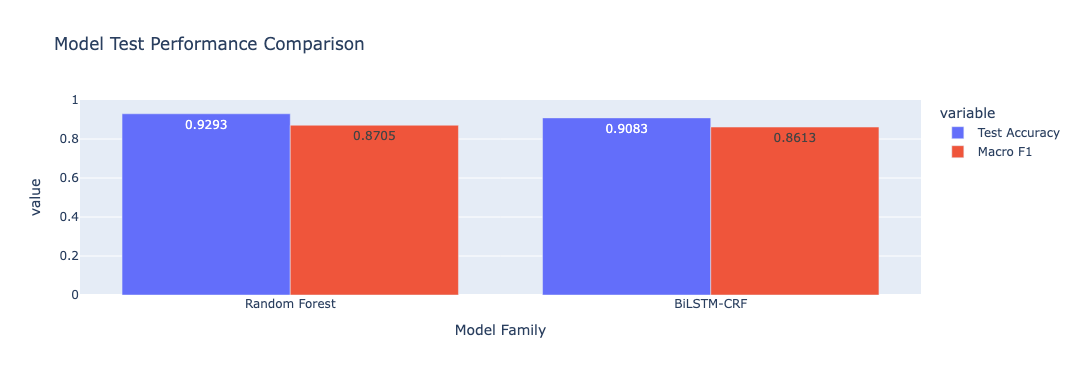

In [7]:
import json

metrics_path = resolve_path(cfg["paths"]["artifacts_prod"]) / cfg["runtime"]["metrics_file"]
metrics_data = json.loads(metrics_path.read_text(encoding="utf-8"))

summary_rows = [
    {
        "Model": family,
        "Test Accuracy": info["best_test_metrics"]["test_accuracy"],
        "Macro F1": info["best_test_metrics"]["macro_f1"],
        "Latency (ms/sent)": info["best_test_metrics"]["latency_ms"],
    }
    for family, info in metrics_data.items()
]
display(pd.DataFrame(summary_rows))

fig_comp = plot_model_head_to_head(metrics_path, cfg["paths"]["figures"])
fig_comp.show()